# Exercise 6: 1D Ising model with Gibbs sampling
### Ex. 6.1:
  > **goal**: implement Gibbs sampling for the 1D Ising model, then run a series of simulations at
  > - $T \in [0.5, 2.0]$
  > - $N_{part} = 50$ and $J = 1$
  > - $N_{steps} \geq 10^5$
  >
  > using both the Metropolis algorithm and Gibbs sampling.
  >
  > Compare measurements of $U(N, T)\big|_{h = 0}$, $M(N, T)\big|_{h = 0.02}$, $C(N, T)\big|_{h = 0}$ and $\chi (N, T)\big|_{h = 0}$ for both algorithms and compare them with analytical results.

First we implement *Gibbs sampling*: the main simulation loop calls for `System`'s `step()` function:
```cpp
  for (int block = 0; block < nblocks; block++) {
    for (int step = 0; step < nsteps; step++) {
      sys->step(); // THIS ONE
      sys->measure();
    }
    sys->end_block(block);
  }
```

The `step()` function is declared as an `std::function<void()>` object in the `System` class, and is declared at runtime for its derived classes (`IsingSystem` and `LJSystem`) after reading the settings files.

In particular, in `IsingSystem`'s constructor we have
```cpp
    if (token == "ALGORITHM") {
      line_stream >> token;
      if (token == "GIBBS") {
        log_stream
            << "ALGORITHM: GIBBS"
            << std::endl;
        step = [this]() { _step_ising(); };
        _attempt_flip = [this](int k) { return _flip_gibbs(k); };
      } else if (token == "METROPOLIS") {
        log_stream
            << "ALGORITHM: METROPOLIS"
            << std::endl;
        step = [this]() { _step_ising(); };
        _attempt_flip = [this](int k) { return _flip_metropolis(k); };
      } else {
        throw std::runtime_error(
            "Error: unrecognized algorithm in \'input/ising_settings.dat\'.");
      }
    }
```

which sets `step()` by referencing the same function `_step_ising()`
```cpp
void IsingSystem::_step_ising() {
  for (int i = 0; i < _npart; i++) {
    int chosen = static_cast<int>(_rng.rannyu() * _npart);
    if (chosen < 0 || chosen >= _npart) {
      throw std::runtime_error(
          "A particle index has been generated out of bounds:" +
          std::to_string(chosen) + ".");
    }

    if (_attempt_flip(chosen)) {
      _particles(chosen).flip_spin();
    }
  }
}
```

***note**: this doesn't attempt a flip on all particles at every step, but attempts `_npart` flips aimed at random particles (possibly the same particle multiple times).



The only difference between the Metropolis algorithm and Gibbs is the `_attempt_flip(int)` function, set in the same constructor code above by referencing one of two functions
```cpp
bool IsingSystem::_flip_metropolis(int k) {
  double delta_E = 2.0 * _particles(k).get_spin() *
                   (_J * (_particles(pbc(k + 1)).get_spin() +
                          _particles(pbc(k - 1)).get_spin()) +
                    _H);
  return _rng.rannyu() < exp(-_beta * delta_E);
}

bool IsingSystem::_flip_gibbs(int k) {
  double prob_spinup =
      1 / (1 + std::exp(-2 * _beta *
                        (_J * (_particles(pbc(k - 1)).get_spin() +
                               _particles(pbc(k + 1)).get_spin()) +
                         _H)));


  int target_spin;
  if (_rng.rannyu() < prob_spinup) {
    target_spin = 1;
  } else {
    target_spin = -1;
  }

  return _particles(k).get_spin() != target_spin;
}
```

Their difference is that, while the Metropolis method computes the eventual *energy difference* caused by the flip and then accepts the flip with probability $$\mathrm{P(\textit{flip})} = \exp\{-\beta \Delta E\}$$ the Gibbs sampling method computes the *spin-up Boltzmann weight $$\mathrm{P}(s_i = +1) = (1 + e^{ -\beta E_i[s_i = +1] })^{-1}$$* and generates the new value of the spin.

After running **four** *1D Ising* series of simulations (two for each algorithm, one with $h=0.0$ and one with $h=0.02$) with the parameters above, we can load the resulting measurements:

In [21]:
import numpy as np
import pandas as pd
from pathlib import Path
import glob
import sys

PROPERTIES = [
  ("e", "energy_per_particle.csv", "Energy per particle", "$E/N$"),
  ("c", "specific_heat.csv", "Specific heat", "$C_V / N$"),
  ("m", "magnetization.csv", "Magnetization per particle", "$M / N\\quad(h=0.02)$"),
  ("x", "susceptibility.csv", "Susceptibility", "$\\chi / N$")
]

METHODS = [
  ("Metropolis", "METROPOLIS", "#B4708A"),
  ("Gibbs", "GIBBS", "#5D7EA8")
]

DIR = "sim_results/ex6"

def load_data_alt():
  data = {method: [] for _, method, _ in METHODS}

  for _, method, _ in METHODS:
    for dir in sorted(glob.glob(f"{DIR}/{method}_T*")):
      logfile_path = Path(dir) / 'logfile.log'
      if not logfile_path.exists():
        sys.exit(f"Error: {logfile_path} does not exist.")
      with open(logfile_path, 'r') as logfile:
        lines = [l for l in logfile if 'TEMP_EQUIL:' in l]
        if not lines:
          sys.exit(f"Error: {logfile_path} does not contain any line matching 'TEMP_EQUIL:'.")
      T = float(lines[0].split()[1])
      datapoint = {'T': T}

      for key, filename, _, _ in PROPERTIES:
        df = pd.read_csv(Path(dir) / filename, sep=',')
        datapoint[key] = df.iloc[-1, 3]
        datapoint[key + '_err'] = np.maximum(df.iloc[-1, 4], 0)

      data[method].append(datapoint)

  return {method: pd.DataFrame(rows).sort_values('T').reset_index(drop=True)
        for method, rows in data.items()}


# def load_data(results_dir):
  data = []

  for dir in sorted(glob.glob(f"{results_dir}/T_*")):
    logfile_path = Path(dir) / 'logfile.log'
    if not logfile_path.exists():
      sys.exit(f"Error: {logfile_path} does not exist.")
    with open(logfile_path, 'r') as logfile:
      lines = [l for l in logfile if 'TEMPERATURE:' in l]
      if not lines:
        sys.exit(f"Error: {logfile_path} does not contain any line matching 'TEMPERATURE:'.")
    T = float(lines[0].split()[1])

    datapoint = {'T': T}
    for key, filename, _, _ in PROPERTIES:
      df = pd.read_csv(Path(dir) / filename, sep=',')
      datapoint[key] = df.iloc[-1, 3]
      datapoint[key + '_err'] = np.maximum(df.iloc[-1, 4], 0)

    data.append(datapoint)

  return pd.DataFrame(data).sort_values('T').reset_index(drop=True)

# metrop_dir = "sim_results/ising_metropolis_combined"
# gibbs_dir = "sim_results/ising_gibbs_combined"

data = load_data_alt()
# metrop_data = load_data(metrop_dir)
# gibbs_data = load_data(gibbs_dir)

compute each theoretical expectation

In [19]:
Tmin = 0.5
Tmax = 2.0
T = np.linspace(Tmin, Tmax, int((Tmax - Tmin)*500))
N = 50
J = 1.0
H = 0.02

def theory(T, N, J, H):
  beta = 1 / T
  tanh = np.tanh(beta * J)
  tanhN = tanh**N
  coth = 1 / tanh

  e = -J * (tanh + coth * tanhN) / (1 + tanhN)
  c = ((beta * J)**2) * ((1 + tanhN + (N - 1) * tanh**2 + (N - 1) * coth**2 * tanhN) / (1 + tanhN)
                            - N * ((tanh + coth * tanhN) / (1 + tanhN))**2)
  x = beta * np.exp(2 * beta * J) * (1 - tanhN) / (1 + tanhN)

  sinh = np.sinh(beta * H)
  cosh = np.cosh(beta * H)
  l1 = np.exp(beta * J) * cosh + np.sqrt(np.exp(2 * beta * J) * cosh * cosh - 2 * np.sinh(2 * beta * J))
  l2 = np.exp(beta * J) * cosh - np.sqrt(np.exp(2 * beta * J) * cosh * cosh - 2 * np.sinh(2 * beta * J))
  l2l1 = l2 / l1
  C = np.exp(beta * J) * cosh / np.sqrt(np.exp(2 * beta * J) * cosh * cosh - 2 * np.sinh(2 * beta * J))

  # m = np.exp(beta * J) * sinh * ((1 + C) / l1 + (l2l1**N) * (1 - C) / (l2 * l2)) / (1 + l2l1**N)
  m = np.exp(beta * J) * sinh * ((1 + C) / l1 + (l2l1**N) * (1 - C) / l2) / (1 + l2l1**N)

  return {'e': e, 'c': c, 'm': m, 'x': x}

theory_data = theory(T, N, J, H)

and plot them all

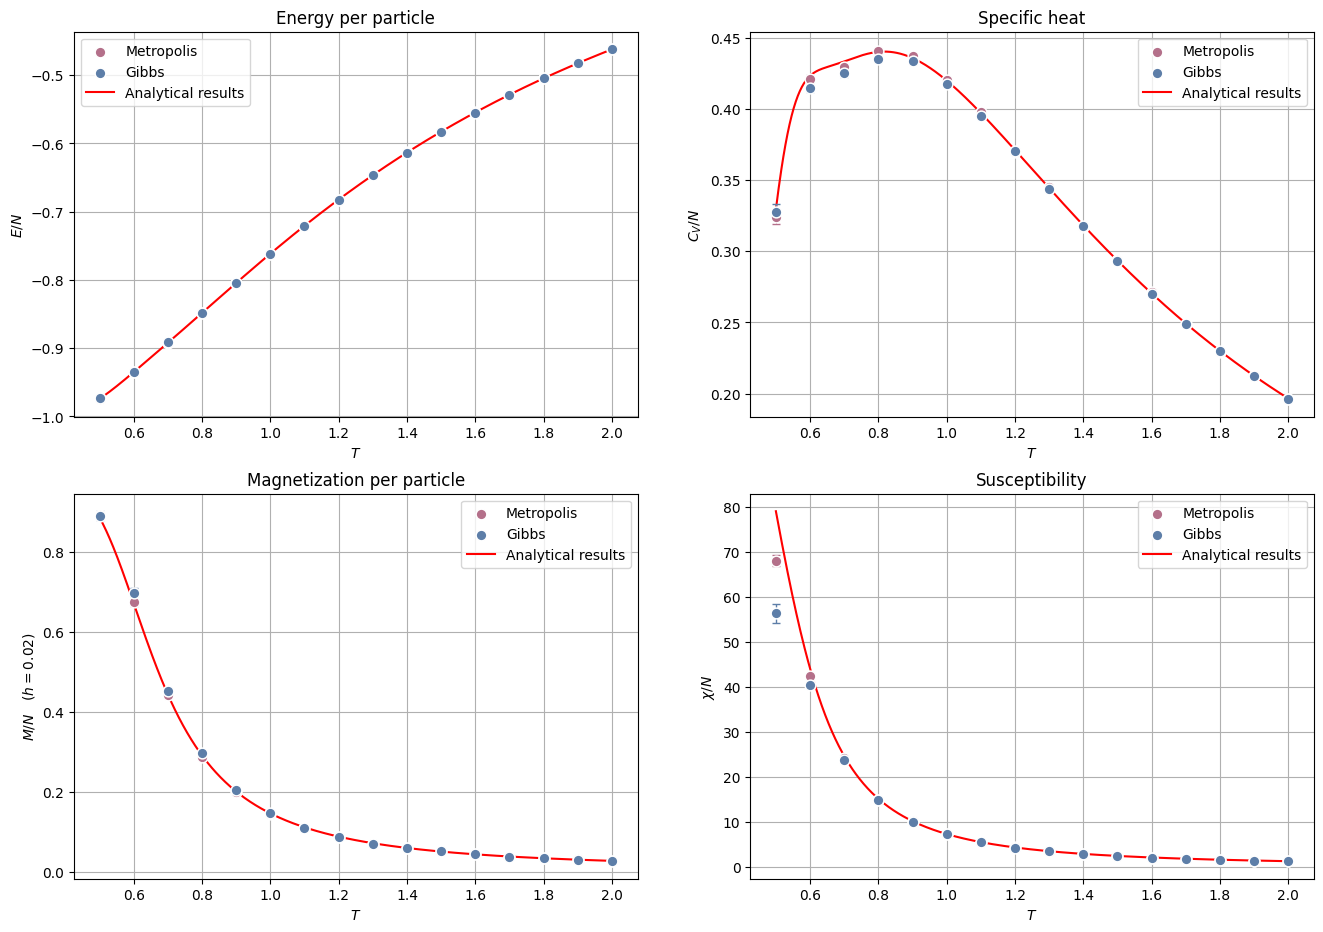

In [22]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(8*2,5.5*2))

def scatter_error(ax, x_data, y_data, yerr, label, color):
  ax.errorbar(x_data, y_data, yerr=yerr, color=color, fmt='none', elinewidth=1.0, capsize=3, zorder=3)
  ax.scatter(x_data, y_data, color=color, label=label, edgecolor='white', linewidth=1.1, s=60, zorder=4)

for ax, (key, _, title, label) in zip(axs.flat, PROPERTIES):
  # scatter_error(ax, metrop_data['T'], metrop_data[key], yerr=metrop_data[key + "_err"], label="Metropolis algorithm", color="#5D7EA8")
  # scatter_error(ax, gibbs_data['T'], gibbs_data[key], yerr=gibbs_data[key + "_err"], label="Gibbs sampling", color="#B4708A")
  for name, method, style in METHODS:
    scatter_error(ax, data[method]['T'], data[method][key], yerr=data[method][key + "_err"], label=name, color=style)
  ax.plot(T, theory_data[key], label="Analytical results", color='r')
  ax.set_title(title)
  ax.set_xlabel("$T$")
  ax.set_ylabel(label)
  ax.grid(True)
  ax.legend()

***note**: each simulation was set at $100$ blocks of $10^4$ steps each (each step tries to flip $N_{part}$ random particles), and was preceeded by 16 blocks (2000 steps each) of thermalisation phase.*